<a href="https://colab.research.google.com/github/praptibhayde56/Responsible-AI-Model-Evaluation/blob/main/DLEXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip -q install shap


In [2]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load Titanic dataset
df = sns.load_dataset("titanic")

# Select required columns
df = df[
    ["survived", "sex", "pclass", "age",
     "sibsp", "parch", "fare", "embarked"]
].copy()

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())
print("\nMissing Values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset Shape: (891, 8)


,survived,sex,pclass,age,sibsp,parch,fare,embarked
0,0,male,3,22.0,1,0,7.2500,S
1,1,female,1,38.0,1,0,71.2833,C
2,1,female,3,26.0,0,0,7.9250,S
3,1,female,1,35.0,1,0,53.1000,S
4,0,male,3,35.0,0,0,8.0500,S



Missing Values:
survived      0
sex           0
pclass        0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


In [3]:

# Separate features and target
X = df.drop("survived", axis=1)
y = df["survived"]

# Define categorical and numerical columns
categorical = ["sex", "embarked"]
numerical = ["pclass", "age", "sibsp", "parch", "fare"]

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), categorical)
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build the model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

# Train model
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Model training completed successfully!
Training samples: 712
Testing samples: 179


Confusion Matrix:
[[99 11]
 [21 48]]


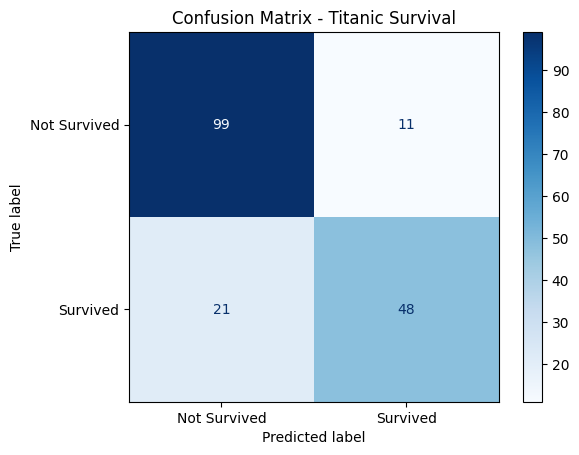


Classification Report:

              precision    recall  f1-score   support

Not Survived       0.82      0.90      0.86       110
    Survived       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179


Overall Evaluation Metrics:


,Metric,Value
0,Accuracy,0.8212
1,Precision,0.8136
2,Recall,0.6957
3,F1-Score,0.7500


In [4]:

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Titanic Survival")
plt.show()

# Classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Survived", "Survived"],
    zero_division=0
))

# Calculate overall metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Value": [accuracy, precision, recall, f1]
})

results["Value"] = results["Value"].round(4)

print("\nOverall Evaluation Metrics:")
display(results)


Prediction Accuracy by Sex:


,Prediction Accuracy
sex,
female,0.868852
male,0.796610


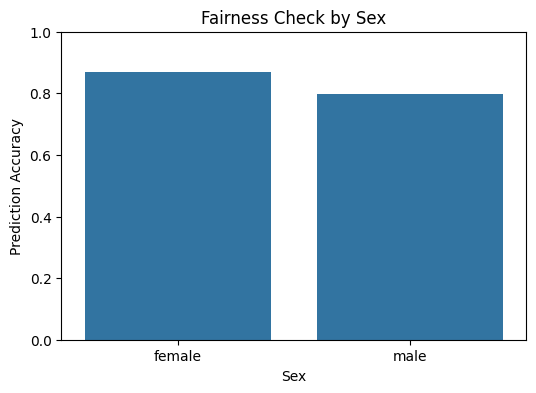

Accuracy gap between groups: 7.22 percentage points


In [5]:

# Create evaluation dataframe
eval_df = X_test.copy()

eval_df["Actual"] = y_test.to_numpy()
eval_df["Predicted"] = y_pred
eval_df["Correct"] = (
    eval_df["Actual"] == eval_df["Predicted"]
).astype(int)

# Compare prediction accuracy by sex
bias_report = eval_df.groupby("sex")["Correct"].mean()

print("Prediction Accuracy by Sex:")
display(bias_report.rename("Prediction Accuracy"))

# Visualize the comparison
plt.figure(figsize=(6, 4))

sns.barplot(
    x=bias_report.index,
    y=bias_report.values
)

plt.ylim(0, 1)
plt.ylabel("Prediction Accuracy")
plt.xlabel("Sex")
plt.title("Fairness Check by Sex")
plt.show()

# Calculate accuracy gap
accuracy_gap = (
    bias_report.max() - bias_report.min()
) * 100

print(f"Accuracy gap between groups: {accuracy_gap:.2f} percentage points")


Generating SHAP summary plot...


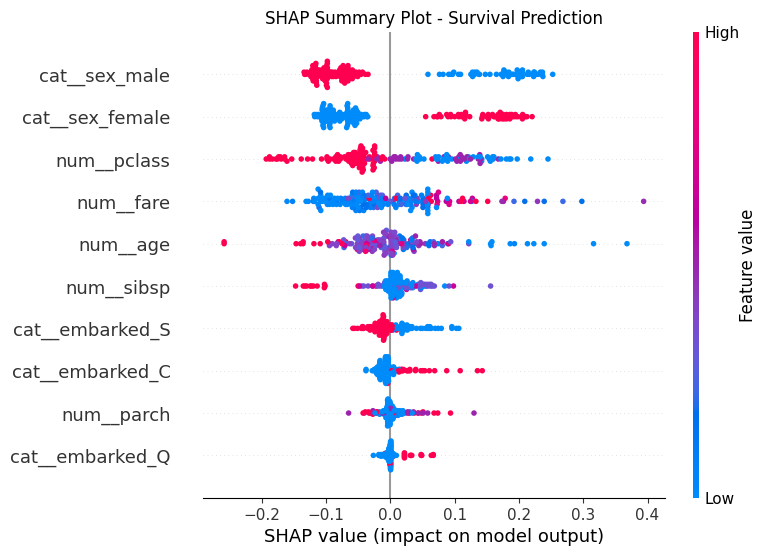

SHAP summary plot saved successfully!


In [6]:

# Transform the test data using the fitted preprocessor
X_test_processed = model.named_steps[
    "preprocessor"
].transform(X_test)

# Get trained Random Forest classifier
rf = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Build SHAP explainer
explainer = shap.TreeExplainer(rf)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_processed)

# Handle SHAP output formats across versions
if isinstance(shap_values, list):
    values_survived = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    values_survived = shap_values[:, :, 1]
else:
    values_survived = shap_values

print("Generating SHAP summary plot...")

shap.summary_plot(
    values_survived,
    X_test_processed,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Summary Plot - Survival Prediction")
plt.savefig(
    "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("SHAP summary plot saved successfully!")


Actual Class: 0
Predicted Class: 0
Predicted Probability of Survival: 0.155


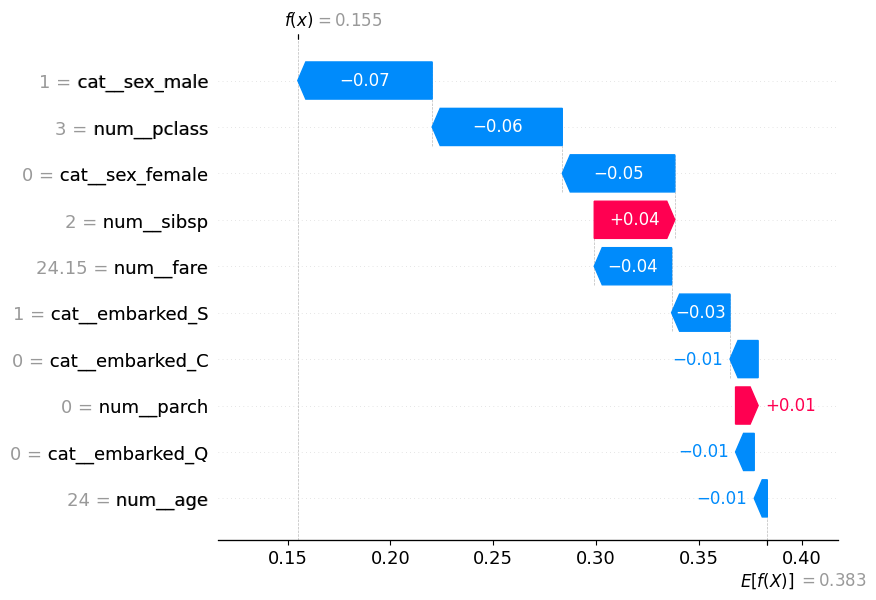


Individual prediction explanation generated!


In [7]:

# Select one test sample
sample_idx = 0

# Get SHAP values and base value
sample_values = values_survived[sample_idx]

base_value = np.asarray(explainer.expected_value).reshape(-1)

if len(base_value) > 1:
    base_value = base_value[1]
else:
    base_value = base_value[0]

# Display actual and predicted results
print("Actual Class:", y_test.iloc[sample_idx])
print("Predicted Class:", y_pred[sample_idx])
print("Predicted Probability of Survival:",
      round(model.predict_proba(X_test.iloc[[sample_idx]])[0, 1], 4))

# Create SHAP explanation
explanation = shap.Explanation(
    values=sample_values,
    base_values=base_value,
    data=X_test_processed[sample_idx],
    feature_names=feature_names
)

# Display waterfall plot
shap.plots.waterfall(explanation, max_display=12)

print("\nIndividual prediction explanation generated!")


In [8]:

from google.colab import files
files.download("shap_summary.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>